In [17]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

# START CODE

# END CODE
#from sklearn.model_selection import train_test_split

from matplotlib import pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
training_path = "/content/drive/MyDrive/Colab Notebooks/customer_train.csv" # sesuaikan dengan struktur file di GDrive masing-masing
test_path = "/content/drive/MyDrive/Colab Notebooks/customer_test.csv"

# START CODE
df_customer_train = pd.read_csv(training_path)
df_customer_test = pd.read_csv(test_path)
# END CODE

In [ ]:
TARGET = "churned"
ID_COLUMN = "customer_id"

CATEGORICAL_COLUMNS = [
    "country",
    "gender",
    "membership_tier",
    "preferred_category",
    "preferred_device",
    "preferred_payment_method",
    "acquisition_channel",
]

NUMERIC_COLUMNS = [
    "age",
    "total_orders",
    "total_spend_usd",
    "avg_order_value_usd",
    "days_since_last_purchase",
    "reviews_given",
    "avg_review_score",
    "returns_made",
    "wishlist_items",
    "newsletter_subscribed",
    "customer_tenure_days",
    "orders_per_year",
    "reviews_per_order",
    "returns_per_order",
]

## k-Nearest Neighbor

In [18]:
# 1. Data Preparation
X_train = df_customer_train[NUMERIC_COLUMNS]
y_train = df_customer_train[TARGET]

# START CODE
X_test = df_customer_test[NUMERIC_COLUMNS]
y_test = df_customer_test[TARGET]

# END CODE

In [19]:
# Periksa ukuran data
print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji:", X_test.shape)
print("Ukuran label latih:", y_train.shape)
print("Ukuran label uji:", y_test.shape)

Ukuran data latih: (6400, 14)
Ukuran data uji: (1600, 14)
Ukuran label latih: (6400,)
Ukuran label uji: (1600,)


In [20]:
num_neighbor = [3,5,7,9,11,13,15,17,19,21,23]
all_acc = []
all_prec = []
all_rec = []
all_f1 = []

for i in num_neighbor:
    # 2. Create the Model
    # START CODE
    model = KNeighborsClassifier(n_neighbors=i)
    # END CODE

    # 3. Train the Model
    model.fit(X_train, y_train)

    # 4. Test the Model
    y_pred = model.predict(X_test)

    # 5. Evaluation Metrics
    acc = metrics.accuracy_score(y_test, y_pred)
    prec = metrics.precision_score(y_test, y_pred, average="macro")
    rec = metrics.recall_score(y_test, y_pred, average="macro")
    f1 = metrics.f1_score(y_test, y_pred, average="macro")

    # record all metrics
    all_acc.append(acc)
    all_prec.append(prec)
    all_rec.append(rec)
    all_f1.append(f1)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


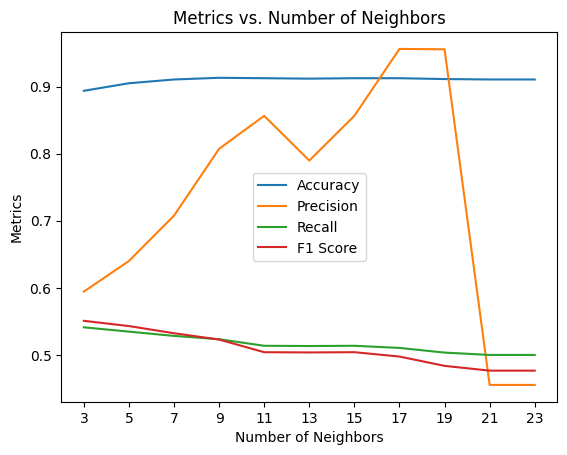

In [ ]:
plt.plot(num_neighbor, all_acc, label='Accuracy')
plt.plot(num_neighbor, all_prec, label='Precision')
plt.plot(num_neighbor, all_rec, label='Recall')
plt.plot(num_neighbor, all_f1, label='F1 Score')
plt.xlabel('Number of Neighbors')
plt.ylabel('Metrics')
plt.title('Metrics vs. Number of Neighbors')
plt.legend()
plt.xticks(num_neighbor)
plt.show()